# Predicción del riesgo de hipoglucemia asociado a la actividad física en personas con diabetes

## Dataset original: CGMacros

**CGMacros: A Scientific Dataset for Personalized Nutrition and Diet Monitoring**

*CGMacros: un conjunto de datos científicos para la nutrición personalizada y el seguimiento de la alimentación.*

CGMacros es un conjunto de datos de investigación que contiene registros de personas sin diabetes, con prediabetes y con diabetes tipo 2. Incluye mediciones continuas de glucosa, actividad física, alimentación y otras variables fisiológicas.

Su objetivo original es contribuir al estudio de las respuestas glucémicas individuales y su relación con la alimentación y otros factores cotidianos.

## Mi proyecto de Aprendizaje Automático

A partir de CGMacros, desarrollé un proyecto para estudiar la relación entre la actividad física y la hipoglucemia en personas con diabetes.
Utilizé los registros de glucosa para identificar la presencia o ausencia de hipoglucemia y variables relacionadas con la actividad física para desarrollar un **modelo de clasificación binaria**.
Pregunta del proyecto: ¿Es posible identificar el riesgo de hipoglucemia asociado a la actividad física mediante Aprendizaje Automático?

### Utilidad del proyecto

Este proyecto busca explorar si es posible anticipar episodios de hipoglucemia utilizando los valores medios de glucosa y actividad física (METs) registrados durante los 60 minutos anteriores, para estimar el riesgo de que comience un episodio en los siguientes 60 minutos.

Esta anticipación podría resultar útil para personas con diabetes y profesionales de la salud, al aportar información que, en el futuro, podría contribuir a la prevención y al seguimiento de estos episodios.



### Relación entre actividad física e hipoglucemia

Durante la actividad física, los músculos aumentan el consumo de glucosa para obtener energía. Además, el ejercicio puede aumentar la sensibilidad a la insulina, facilitando la entrada de glucosa desde la sangre hacia las células.

En una persona con diabetes, estos efectos pueden favorecer un descenso excesivo de la glucosa y aumentar el riesgo de hipoglucemia durante el ejercicio o después de haberlo realizado.

Sin embargo, la respuesta depende de diferentes factores, como la intensidad y duración del ejercicio, la glucosa previa, la alimentación y el tratamiento utilizado.

Por este motivo, en este proyecto se analiza la actividad física mediante los METs junto con la glucosa previa para estudiar su relación con la aparición posterior de hipoglucemia.

## Definición de hipoglucemia y actividad física

### Hipoglucemia

La hipoglucemia ocurre cuando la glucosa en sangre desciende por debajo de **70 miligramos por decilitro**.

En este trabajo se consideró un **episodio de hipoglucemia** cuando la glucosa permaneció por debajo de ese valor durante **al menos 15 minutos consecutivos**.

De esta manera se evita considerar como episodio una disminución aislada y muy breve de la glucosa.

### Actividad física

En el conjunto de datos CGMacros, la actividad física fue registrada mediante un **dispositivo Fitbit**.

Este dispositivo estima la intensidad de la actividad mediante una medida llamada **MET**, que permite comparar el esfuerzo realizado con el gasto energético del cuerpo en reposo.

Cuanto mayor es el valor de MET, mayor es la intensidad de la actividad.



Para facilitar su interpretación, la actividad se clasificó de la siguiente manera:

- **Actividad ligera:** menos de 3 MET. Por ejemplo, caminar lentamente o realizar tareas domésticas livianas.
- **Actividad moderada:** entre 3 y 5,9 MET. Por ejemplo, caminar a paso rápido o andar en bicicleta a ritmo tranquilo.
- **Actividad vigorosa:** 6 MET o más. Por ejemplo, correr, subir escaleras rápidamente o andar en bicicleta a ritmo intenso.

Para este trabajo se consideraron períodos de actividad física aquellos con una intensidad de **3 MET o más**, es decir, actividad moderada o vigorosa.

### Aclaración sobre los valores de MET

En CGMacros, los valores de MET registrados por Fitbit están almacenados multiplicados por 10.

Por este motivo, los dividí por 10 para expresarlos en su valor real y facilitar su interpretación.

## Información de los participantes de CGMacros

El archivo `bio.csv` contiene información individual de los participantes del estudio, incluyendo características demográficas, antropométricas y resultados de laboratorio.

A diferencia de los archivos individuales de CGMacros, que contienen mediciones de glucosa y actividad física registradas a lo largo del tiempo, este archivo permite conocer las características de las personas que participaron en la investigación.


## Selección de los participantes para el análisis

Para desarrollar el modelo de Aprendizaje Automático se usarán datos de los participantes con diabetes incluidos en CGMacros.

Para identificar los participantes que serán incluidos en el análisis utilizaré la información disponible en el archivo `bio.csv`.



In [2]:
import pandas as pd


In [3]:
bio = pd.read_csv("bio.csv")

bio.head()

,subject,Age,Gender,BMI,Body weight,Height,Self-identify,A1c PDL (Lab),Fasting GLU - PDL (Lab),Insulin,...,LDL (Cal),VLDL (Cal),Cho/HDL Ratio,Collection time PDL (Lab),#1 Contour Fingerstick GLU,Time (t),#2 Contour Fingerstick GLU,Time (t).1,#3 Contour Fingerstick GLU,Time (t).2
0,1,27,M,22.265239,133.8,65.0,Hispanic/Latino,5.4,91,2.5,...,130,13,2.9,11:06:00 AM,89,9:40,73,12:11,81,13:18
1,2,49,F,30.946742,169.2,62.0,Hispanic/Latino,5.5,93,14.8,...,78,12,2.0,7:38:00 AM,91,7:52,123,9:21,80,10:22
2,3,59,F,26.948690,157.0,64.0,Hispanic/Latino,6.5,118,17.4,...,90,31,2.6,7:25:00 AM,119,7:38,166,9:23,98,10:23
3,4,33,F,42.384279,262.6,66.0,Hispanic/Latino,5.5,105,19.4,...,164,60,5.8,7:20:00 AM,109,7:37,110,9:04,90,10:01
4,5,51,F,30.957534,172.0,62.5,Hispanic/Latino,6.6,144,12.9,...,157,78,7.1,7:45:00 AM,139,8:59,215,10:52,130,11:54


In [4]:
bio.columns.tolist()

['subject',
 'Age',
 'Gender',
 'BMI',
 'Body weight ',
 'Height ',
 'Self-identify ',
 'A1c PDL (Lab)',
 'Fasting GLU - PDL (Lab)',
 'Insulin ',
 'Triglycerides',
 'Cholesterol',
 'HDL',
 'Non HDL ',
 'LDL (Cal)',
 'VLDL (Cal)',
 'Cho/HDL Ratio',
 'Collection time PDL (Lab)',
 '#1 Contour Fingerstick GLU',
 'Time (t)',
 ' #2 Contour Fingerstick GLU',
 'Time (t).1',
 '#3 Contour Fingerstick GLU',
 'Time (t).2']

### Identificación de los participantes con diabetes

CGMacros incluye participantes sin diabetes, con prediabetes y con diabetes tipo 2.

Para este proyecto me interesan los participantes con diabetes tipo 2. Según la documentación de CGMacros, este grupo corresponde a los participantes con un valor de HbA1c mayor de 6,4 %.

La HbA1c es un análisis de sangre que refleja el nivel promedio de glucosa de los últimos meses.

Por este motivo, utilicé esta variable para seleccionar los participantes con diabetes tipo 2 que serán incluidos en nuestro análisis.

In [5]:
diabetes = bio[bio["A1c PDL (Lab)"] > 6.4]

In [6]:
diabetes[["subject", "A1c PDL (Lab)"]]

,subject,A1c PDL (Lab)
2,3,6.5
4,5,6.6
11,12,7.1
13,14,7.1
25,28,7.0
27,30,7.6
32,35,8.5
33,36,6.9
34,38,7.2
35,39,8.3


## Resultado de la selección

De acuerdo con la clasificación utilizada en el dataset CGMacros, se seleccionaron los participantes con un valor de HbA1c de laboratorio superior a 6,4 %.

Mediante este criterio se identificaron **14 participantes con diabetes tipo 2**, que constituyen la población de interés para el presente análisis.



## Acceso a los archivos de los participantes

Una vez identificados los 14 participantes con diabetes tipo 2, necesité localizar sus archivos individuales de CGMacros para acceder a sus registros de glucosa y actividad física.



In [7]:
from pathlib import Path

In [8]:
ruta_datos = Path(r"""C:\Users\usuario\Desktop\PROYECTO HIPOGLUCEMIA\CGMacros_dateshifted365\CGMacros""")

In [9]:
carpetas = sorted(ruta_datos.glob("CGMacros-*"))

len(carpetas)

45

Se localizaron 45 carpetas individuales, correspondientes a los participantes disponibles en CGMacros. A partir de ellas utilizaré los archivos de los 14 participantes con diabetes tipo 2 seleccionados previamente.

In [10]:
participantes_diabetes = diabetes["subject"].tolist()

participantes_diabetes

[3, 5, 12, 14, 28, 30, 35, 36, 38, 39, 42, 46, 47, 49]

## Análisis de los participantes seleccionados

A continuación se analizarán los registros de los participantes seleccionados para identificar episodios de hipoglucemia y estudiar la actividad física asociada.

### Carga de los datos de los 14 participantes

 Cada archivo contiene sus registros temporales de glucosa, actividad física y otras variables.

Estos datos serán utilizados para identificar las mediciones de glucosa inferiores a 70 mg/dL y posteriormente analizar los episodios de hipoglucemia.

In [11]:
datos_participantes = {}

for participante in participantes_diabetes:
    nombre = f"CGMacros-{participante:03d}"
    archivo = ruta_datos / nombre / f"{nombre}.csv"
    datos_participantes[nombre] = pd.read_csv(archivo)

len(datos_participantes)

14

In [12]:
for nombre, datos in datos_participantes.items():
    print(nombre, ":", datos.shape[0], "filas,", datos.shape[1], "columnas")

CGMacros-003 : 14565 filas, 15 columnas
CGMacros-005 : 14460 filas, 15 columnas
CGMacros-012 : 14655 filas, 14 columnas
CGMacros-014 : 17250 filas, 14 columnas
CGMacros-028 : 18735 filas, 13 columnas
CGMacros-030 : 15465 filas, 14 columnas
CGMacros-035 : 14400 filas, 14 columnas
CGMacros-036 : 17115 filas, 15 columnas
CGMacros-038 : 14505 filas, 14 columnas
CGMacros-039 : 17205 filas, 14 columnas
CGMacros-042 : 14520 filas, 14 columnas
CGMacros-046 : 14655 filas, 14 columnas
CGMacros-047 : 15690 filas, 14 columnas
CGMacros-049 : 15315 filas, 15 columnas


In [40]:
datos_participantes["CGMacros-003"].info()

<class 'pandas.DataFrame'>
RangeIndex: 14565 entries, 0 to 14564
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Unnamed: 0           14565 non-null  int64         
 1   Timestamp            14565 non-null  datetime64[us]
 2   Libre GL             14565 non-null  float64       
 3   Dexcom GL            14260 non-null  float64       
 4   HR                   14478 non-null  float64       
 5   Calories (Activity)  14565 non-null  float64       
 6   METs                 14565 non-null  int64         
 7   Meal Type            35 non-null     str           
 8   Calories             35 non-null     float64       
 9   Carbs                35 non-null     float64       
 10  Protein              35 non-null     float64       
 11  Fat                  35 non-null     float64       
 12  Fiber                35 non-null     float64       
 13  Amount Consumed      35 non-null     float

## Identificación de episodios de hipoglucemia en los participantes

En cada uno de los 14 participantes analicé los registros de glucosa para identificar episodios de hipoglucemia.

Se considera como episodio de hipoglucemia un período en el que la glucosa permanece por debajo de 70 mg/dL durante al menos 15 minutos, de acuerdo con el criterio de la American Diabetes Association (ADA), 

In [13]:
resultados_episodios = []

for nombre, datos in datos_participantes.items():
    
    datos["Timestamp"] = pd.to_datetime(datos["Timestamp"])
    hipo = datos[datos["Libre GL"] < 70].copy()

    if len(hipo) > 0:
        hipo["Diferencia_tiempo"] = hipo["Timestamp"].diff()

        hipo["Bloque"] = (
            hipo["Diferencia_tiempo"] > pd.Timedelta(minutes=1)
        ).cumsum() + 1

        bloques = hipo.groupby("Bloque").agg(
            Inicio=("Timestamp", "min"),
            Fin=("Timestamp", "max")
        )

        bloques["Duracion"] = bloques["Fin"] - bloques["Inicio"]

        episodios = (
            bloques["Duracion"] >= pd.Timedelta(minutes=15)
        ).sum()

    else:
        episodios = 0

    resultados_episodios.append({
        "Participante": nombre,
        "Episodios": episodios
    })

resumen_episodios = pd.DataFrame(resultados_episodios)

resumen_episodios

,Participante,Episodios
0,CGMacros-003,4
1,CGMacros-005,5
2,CGMacros-012,0
3,CGMacros-014,1
4,CGMacros-028,2
5,CGMacros-030,1
6,CGMacros-035,0
7,CGMacros-036,18
8,CGMacros-038,1
9,CGMacros-039,3


### Registro individual de los episodios detectados

Para analizar la actividad física previa a cada episodio necesitamos conocer su momento de inicio y finalización.

Por este motivo, registré individualmente los episodios identificados en los 14 participantes, conservando el participante al que pertenecen y las fechas y horas de inicio y fin.

In [14]:
episodios_detectados = []

for nombre, datos in datos_participantes.items():

    datos["Timestamp"] = pd.to_datetime(datos["Timestamp"])
    hipo = datos[datos["Libre GL"] < 70].copy()

    if len(hipo) > 0:
        hipo["Diferencia_tiempo"] = hipo["Timestamp"].diff()

        hipo["Bloque"] = (
            hipo["Diferencia_tiempo"] > pd.Timedelta(minutes=1)
        ).cumsum() + 1

        bloques = hipo.groupby("Bloque").agg(
            Inicio=("Timestamp", "min"),
            Fin=("Timestamp", "max")
        )

        bloques["Duracion"] = bloques["Fin"] - bloques["Inicio"]
        bloques = bloques[
            bloques["Duracion"] >= pd.Timedelta(minutes=15)
        ]

        for _, episodio in bloques.iterrows():
            episodios_detectados.append({
                "Participante": nombre,
                "Inicio": episodio["Inicio"],
                "Fin": episodio["Fin"]
            })

episodios_detectados = pd.DataFrame(episodios_detectados)

episodios_detectados

,Participante,Inicio,Fin
0,CGMacros-003,2020-03-11 15:50:00,2020-03-11 17:34:00
1,CGMacros-003,2020-03-12 04:17:00,2020-03-12 05:17:00
2,CGMacros-003,2020-03-12 13:04:00,2020-03-12 13:42:00
3,CGMacros-003,2020-03-17 12:14:00,2020-03-17 12:32:00
4,CGMacros-005,2020-08-17 13:52:00,2020-08-17 14:39:00
5,CGMacros-005,2020-08-18 00:43:00,2020-08-18 01:33:00
6,CGMacros-005,2020-08-18 02:19:00,2020-08-18 04:00:00
7,CGMacros-005,2020-08-18 04:35:00,2020-08-18 05:13:00
8,CGMacros-005,2020-08-19 04:43:00,2020-08-19 05:01:00
9,CGMacros-014,2023-05-17 02:47:00,2023-05-17 03:48:00


## Actividad física previa a los episodios de hipoglucemia

Para estudiar la posible relación entre actividad física e hipoglucemia, analizamos la hora anterior al inicio de cada episodio detectado.

Utilizamos los MET para representar la intensidad de la actividad física y contamos cuántos registros presentaron valores de 3 MET o más, correspondientes a actividad de intensidad moderada o superior.

In [15]:
actividad_previa = []

for _, episodio in episodios_detectados.iterrows():

    participante = episodio["Participante"]
    datos = datos_participantes[participante].copy()

    if "METs" not in datos.columns:
        continue

    datos["Timestamp"] = pd.to_datetime(datos["Timestamp"])
    datos["METs_reales"] = datos["METs"] / 10

    inicio = episodio["Inicio"]
    hora_antes = inicio - pd.Timedelta(hours=1)

    periodo = datos[
        (datos["Timestamp"] >= hora_antes) &
        (datos["Timestamp"] < inicio)
    ]

    registros_activos = (periodo["METs_reales"] >= 3).sum()

    actividad_previa.append({
        "Participante": participante,
        "Inicio_episodio": inicio,
        "Registros_>=3_MET": registros_activos
    })

actividad_previa = pd.DataFrame(actividad_previa)

actividad_previa

,Participante,Inicio_episodio,Registros_>=3_MET
0,CGMacros-003,2020-03-11 15:50:00,2
1,CGMacros-003,2020-03-12 04:17:00,1
2,CGMacros-003,2020-03-12 13:04:00,53
3,CGMacros-003,2020-03-17 12:14:00,28
4,CGMacros-005,2020-08-17 13:52:00,8
5,CGMacros-005,2020-08-18 00:43:00,0
6,CGMacros-005,2020-08-18 02:19:00,0
7,CGMacros-005,2020-08-18 04:35:00,0
8,CGMacros-005,2020-08-19 04:43:00,0
9,CGMacros-014,2023-05-17 02:47:00,0


## Análisis de la actividad física previa a los episodios de hipoglucemia

Una vez identificados los episodios de hipoglucemia en los participantes con diabetes tipo 2, se analizará la actividad física registrada durante los 60 minutos anteriores al inicio de cada episodio.

El objetivo es explorar si existe una posible relación entre la actividad física y la aparición de hipoglucemia.


In [16]:
total_episodios = len(actividad_previa)

episodios_con_actividad = (
    actividad_previa["Registros_>=3_MET"] > 0
).sum()

episodios_sin_actividad = (
    actividad_previa["Registros_>=3_MET"] == 0
).sum()

print("Episodios analizados:", total_episodios)
print("Con registros de actividad >=3 MET:", episodios_con_actividad)
print("Sin registros de actividad >=3 MET:", episodios_sin_actividad)

Episodios analizados: 39
Con registros de actividad >=3 MET: 21
Sin registros de actividad >=3 MET: 18




Se analizaron 39 episodios de hipoglucemia en participantes con registros de METs disponibles.

De estos episodios, **21 presentaron actividad física de intensidad moderada o superior (≥3 MET) durante la hora previa**, mientras que **18 no presentaron este nivel de actividad**.

Este resultado muestra que en una parte de los episodios existió actividad física  moderada o superior previa.

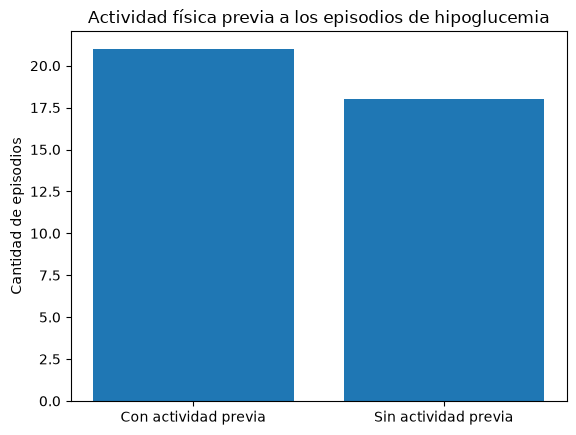

In [17]:
import matplotlib.pyplot as plt

categorias = ["Con actividad previa", "Sin actividad previa"]
cantidades = [episodios_con_actividad, episodios_sin_actividad]

plt.bar(categorias, cantidades)

plt.title("Actividad física previa a los episodios de hipoglucemia")
plt.ylabel("Cantidad de episodios")

plt.show()

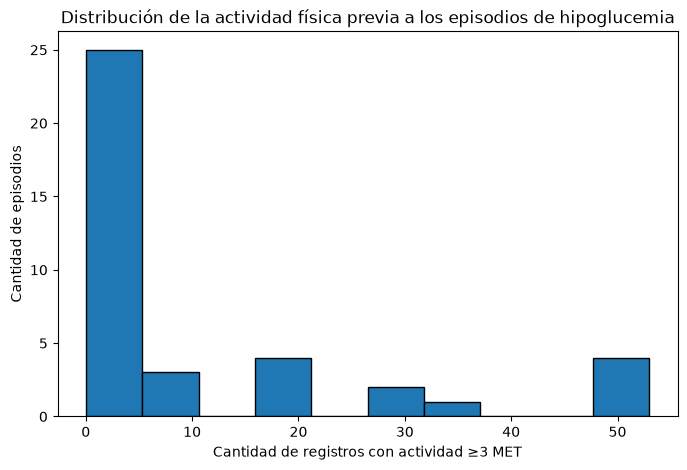

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    actividad_previa["Registros_>=3_MET"],
    bins=10,
    edgecolor="black"
)

plt.xlabel("Cantidad de registros con actividad ≥3 MET")
plt.ylabel("Cantidad de episodios")
plt.title("Distribución de la actividad física previa a los episodios de hipoglucemia")

plt.show()

### Interpretación de los gráficos

De los 39 episodios analizados, 21 presentaron al menos un registro de actividad de intensidad moderada o superior (≥3 MET) durante la hora previa, mientras que 18 no presentaron este nivel de actividad.

El histograma permite observar que la cantidad de registros de actividad previa no fue igual en todos los episodios: algunos presentaron poca o ninguna actividad moderada, mientras que otros mostraron una mayor cantidad de registros con ≥3 MET.

Estos resultados muestran que existe variabilidad en la actividad física previa a los episodios de hipoglucemia.

## Preparación de los datos para Machine Learning

Para desarrollar el modelo de clasificación se definirán dos tipos de situaciones:

- **1 = Con hipoglucemia:** situaciones en las que posteriormente se produce un episodio de hipoglucemia.
- **0 = Sin hipoglucemia:** situaciones en las que posteriormente no se produce un episodio de hipoglucemia.

El objetivo será analizar si la información disponible antes de cada situación, especialmente la glucosa y la actividad física, permite diferenciar ambos grupos.

### Definición temporal de la predicción

Cada observación corresponde a una ventana temporal de un participante. Se utilizarán los valores medios de glucosa y MET registrados durante los 60 minutos anteriores para predecir si comenzará un episodio de hipoglucemia en los siguientes 60 minutos.

In [19]:
participantes_sin_episodios = resumen_episodios[
    resumen_episodios["Episodios"] == 0
]

participantes_sin_episodios

,Participante,Episodios
2,CGMacros-012,0
6,CGMacros-035,0
10,CGMacros-042,0
11,CGMacros-046,0
12,CGMacros-047,0


### Preparación de los casos con hipoglucemia

Para cada episodio se considera una ventana de **60 minutos de observación** seguida de **60 minutos de predicción**. Se exige continuidad de las mediciones, ausencia de valores faltantes y que no exista hipoglucemia durante la observación.Se eligió un período de predicción de 60 minutos porque permite estudiar la posible aparición de hipoglucemia durante la hora siguiente a las mediciones. Esta duración se adoptó como criterio exploratorio y no representa un intervalo clínicamente validado. 

De la primera hora se calculan **Glucosa_media** y **MET_medio**. Se asigna **Hipoglucemia = 1** cuando el episodio comienza en la hora siguiente. Así se evita utilizar mediciones tomadas después del inicio del episodio como predictores.


In [20]:
# Construimos casos positivos con 60 minutos de observación y 60 de predicción.
casos_hipoglucemia = []

for _, episodio in episodios_detectados.iterrows():
    participante = episodio["Participante"]
    inicio_episodio = episodio["Inicio"]
    datos = datos_participantes[participante].copy()

    if "METs" not in datos.columns:
        continue

    datos["Timestamp"] = pd.to_datetime(datos["Timestamp"])
    datos = datos.sort_values("Timestamp")
    datos["METs_reales"] = datos["METs"] / 10

    # Ventana completa: hora previa y hora posterior.
    comienzo = inicio_episodio - pd.Timedelta(minutes=60)
    fin = comienzo + pd.Timedelta(minutes=120)
    ventana = datos[(datos["Timestamp"] >= comienzo) &
                    (datos["Timestamp"] < fin)]

    # Exigir 120 registros consecutivos de un minuto y sin faltantes.
    if len(ventana) != 120:
        continue
    if not (ventana["Timestamp"].diff().iloc[1:] ==
            pd.Timedelta(minutes=1)).all():
        continue
    if ventana[["Libre GL", "METs_reales"]].isna().any().any():
        continue

    observacion = ventana.iloc[:60]
    futuro = ventana.iloc[60:]

    # No usar episodios ya presentes durante la observación.
    if (observacion["Libre GL"] < 70).any():
        continue
    if not (futuro["Timestamp"] == inicio_episodio).any():
        continue

    casos_hipoglucemia.append({
        "Participante": participante,
        "Glucosa_media": observacion["Libre GL"].mean(),
        "MET_medio": observacion["METs_reales"].mean(),
        "Hipoglucemia": 1
    })

casos_hipoglucemia = pd.DataFrame(
    casos_hipoglucemia,
    columns=["Participante", "Glucosa_media", "MET_medio", "Hipoglucemia"]
)
print("Casos positivos válidos:", len(casos_hipoglucemia))
print("Participantes con casos positivos:", casos_hipoglucemia["Participante"].nunique())
casos_hipoglucemia.head()


Casos positivos válidos: 31
Participantes con casos positivos: 8


,Participante,Glucosa_media,MET_medio,Hipoglucemia
0,CGMacros-003,76.736667,1.280000,1
1,CGMacros-003,76.840000,1.116667,1
2,CGMacros-003,99.233333,5.983333,1
3,CGMacros-003,89.761111,3.081667,1
4,CGMacros-005,82.624444,1.636667,1


### Preparación de casos sin hipoglucemia en los mismos participantes

Se buscarán períodos sin hipoglucemia en los participantes que presentaron episodios, utilizando los registros de glucosa y actividad física.

Para construir los casos negativos se considerarán períodos de 60 minutos de observación, seguidos de otros 60 minutos sin aparición de hipoglucemia.

Esto permitirá comparar situaciones con y sin hipoglucemia dentro de los mismos participantes.

### Selección y verificación de los participantes

Para construir los casos sin hipoglucemia se utilizarán los mismos participantes que presentaron episodios de hipoglucemia. De esta manera, podré comparar situaciones con y sin hipoglucemia dentro del mismo grupo de participantes.

Primero identificaré los participantes que presentaron episodios. Luego verificaré la frecuencia temporal de sus registros, ya que necesitaré conocer el intervalo entre las mediciones para construir correctamente los períodos de observación de 60 minutos.

In [21]:
participantes_positivos = casos_hipoglucemia["Participante"].unique()

print("Participantes disponibles:")
print(participantes_positivos)

print("\nCantidad:", len(participantes_positivos))

Participantes disponibles:
<ArrowStringArray>
['CGMacros-003', 'CGMacros-005', 'CGMacros-014', 'CGMacros-028',
 'CGMacros-030', 'CGMacros-036', 'CGMacros-039', 'CGMacros-049']
Length: 8, dtype: str

Cantidad: 8


In [22]:
for participante in participantes_positivos:
    datos = datos_participantes[participante].copy()

    datos["Timestamp"] = pd.to_datetime(datos["Timestamp"])
    datos = datos.sort_values("Timestamp")

    intervalos = datos["Timestamp"].diff()

    print(
        participante,
        "Intervalo más frecuente:",
        intervalos.mode().iloc[0]
    )

CGMacros-003 Intervalo más frecuente: 0 days 00:01:00
CGMacros-005 Intervalo más frecuente: 0 days 00:01:00
CGMacros-014 Intervalo más frecuente: 0 days 00:01:00
CGMacros-028 Intervalo más frecuente: 0 days 00:01:00
CGMacros-030 Intervalo más frecuente: 0 days 00:01:00
CGMacros-036 Intervalo más frecuente: 0 days 00:01:00
CGMacros-039 Intervalo más frecuente: 0 days 00:01:00
CGMacros-049 Intervalo más frecuente: 0 days 00:01:00


### Resultado de la verificación temporal

En los 8 participantes seleccionados, el intervalo más frecuente entre los registros consecutivos es de **1 minuto**.

Esto confirma que los datos presentan una frecuencia temporal adecuada para construir períodos de observación de **60 minutos** antes de evaluar la aparición o no de hipoglucemia.

In [23]:
for participante in participantes_positivos:
    datos = datos_participantes[participante].copy()

    datos["Timestamp"] = pd.to_datetime(datos["Timestamp"])
    datos = datos.sort_values("Timestamp")

    intervalos = datos["Timestamp"].diff()

    interrupciones = (
        intervalos > pd.Timedelta(minutes=1)
    ).sum()

    print(participante, ":", interrupciones, "interrupciones")

CGMacros-003 : 15 interrupciones
CGMacros-005 : 0 interrupciones
CGMacros-014 : 0 interrupciones
CGMacros-028 : 0 interrupciones
CGMacros-030 : 0 interrupciones
CGMacros-036 : 0 interrupciones
CGMacros-039 : 0 interrupciones
CGMacros-049 : 0 interrupciones


### Control de continuidad temporal

Aunque el intervalo más frecuente entre las mediciones es de 1 minuto, también verificamos si existen interrupciones en los registros.

La mayoría de los participantes no presentó interrupciones, mientras que CGMacros-003 presentó 15. Por este motivo, al construir los casos sin hipoglucemia se utilizarán únicamente períodos con registros continuos, evitando considerar como una ventana completa aquellos períodos en los que falten mediciones.

In [24]:
nuevos_casos_negativos = []

for participante in participantes_positivos:

    datos = datos_participantes[participante].copy()

    datos["Timestamp"] = pd.to_datetime(datos["Timestamp"])
    datos = datos.sort_values("Timestamp").reset_index(drop=True)

    if "METs" not in datos.columns:
        continue

    datos["METs_reales"] = datos["METs"] / 10

    # Ventanas de 60 minutos de observación
    # seguidas de 60 minutos de predicción

    for inicio in range(0, len(datos) - 119, 120):

        ventana = datos.iloc[inicio:inicio + 120]

        observacion = ventana.iloc[:60]
        futuro = ventana.iloc[60:]

        # Comprobar continuidad temporal
        continuo = (
            ventana["Timestamp"].diff().iloc[1:]
            == pd.Timedelta(minutes=1)
        ).all()

        if not continuo:
            continue

        # Excluir ventanas con datos faltantes
        if ventana[["Libre GL", "METs_reales"]].isna().any().any():
            continue

        # Sin hipoglucemia durante ambas horas
        if (ventana["Libre GL"] < 70).any():
            continue

        nuevos_casos_negativos.append({
            "Participante": participante,
            "Glucosa_media": observacion["Libre GL"].mean(),
            "MET_medio": observacion["METs_reales"].mean(),
            "Hipoglucemia": 0
        })

nuevos_casos_negativos = pd.DataFrame(nuevos_casos_negativos)

print("Nuevos casos sin hipoglucemia:",
      len(nuevos_casos_negativos))

print("\nCasos por participante:")

print(
    nuevos_casos_negativos.groupby("Participante").size()
)

Nuevos casos sin hipoglucemia: 950

Casos por participante:
Participante
CGMacros-003    114
CGMacros-005    115
CGMacros-014    125
CGMacros-028    124
CGMacros-030    114
CGMacros-036     99
CGMacros-039    139
CGMacros-049    120
dtype: int64


### Resultado de la construcción de casos sin hipoglucemia

Aplicando estos criterios se obtuvieron **950 casos sin hipoglucemia** correspondientes a los mismos participantes que presentaron episodios.

Cada caso utiliza los primeros **60 minutos como período de observación**, del cual se obtienen la glucosa media y el MET medio, y verifica posteriormente un período de **60 minutos sin hipoglucemia**.

Estos casos constituirán la clase **Hipoglucemia = 0** para el modelo de Machine Learning.

In [25]:
print("Casos positivos:", len(casos_hipoglucemia))
print("Casos negativos:", len(nuevos_casos_negativos))

print("\nParticipantes en ambas clases:")

print(
    set(casos_hipoglucemia["Participante"])
    &
    set(nuevos_casos_negativos["Participante"])
)

Casos positivos: 31
Casos negativos: 950

Participantes en ambas clases:
{'CGMacros-028', 'CGMacros-003', 'CGMacros-039', 'CGMacros-030', 'CGMacros-014', 'CGMacros-005', 'CGMacros-049', 'CGMacros-036'}


### Preparación del conjunto de datos para la validación

En la revisión temporal se observaron **29 casos positivos válidos** y **950 casos negativos**, de 8 participantes.
Los datos se separan en entrenamiento y prueba **por participante**, para evitar que registros de una misma persona aparezcan en ambos conjuntos.


In [26]:
datos_ml_nuevo = pd.concat(
    [casos_hipoglucemia, nuevos_casos_negativos],
    ignore_index=True
)

print("Total de casos:", len(datos_ml_nuevo))

print("\nDistribución de las clases:")
print(datos_ml_nuevo["Hipoglucemia"].value_counts())

print("\nParticipantes:", datos_ml_nuevo["Participante"].nunique())

Total de casos: 981

Distribución de las clases:
Hipoglucemia
0    950
1     31
Name: count, dtype: int64

Participantes: 8


### Separación de los datos por participante

Para evaluar la capacidad de generalización del modelo, se separarán los participantes entre entrenamiento y prueba.

De esta manera, el modelo será evaluado con registros de personas que no participaron en su entrenamiento, evitando compartir información de un mismo participante entre ambos conjuntos.

In [27]:
from sklearn.model_selection import GroupShuffleSplit

separador = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

indice_train, indice_test = next(
    separador.split(
        datos_ml_nuevo,
        groups=datos_ml_nuevo["Participante"]
    )
)

train_nuevo = datos_ml_nuevo.iloc[indice_train]
test_nuevo = datos_ml_nuevo.iloc[indice_test]

print("Participantes en entrenamiento:")
print(train_nuevo["Participante"].unique())

print("\nParticipantes en prueba:")
print(test_nuevo["Participante"].unique())

Participantes en entrenamiento:
<ArrowStringArray>
['CGMacros-003', 'CGMacros-014', 'CGMacros-028', 'CGMacros-030',
 'CGMacros-039', 'CGMacros-049']
Length: 6, dtype: str

Participantes en prueba:
<ArrowStringArray>
['CGMacros-005', 'CGMacros-036']
Length: 2, dtype: str


In [28]:
print("Clases en entrenamiento:")
print(train_nuevo["Hipoglucemia"].value_counts())

print("\nClases en prueba:")
print(test_nuevo["Hipoglucemia"].value_counts())

Clases en entrenamiento:
Hipoglucemia
0    736
1     16
Name: count, dtype: int64

Clases en prueba:
Hipoglucemia
0    214
1     15
Name: count, dtype: int64


### Balance de las clases en entrenamiento

En la revisión temporal, el conjunto de entrenamiento tuvo **15 casos con hipoglucemia y 736 sin hipoglucemia**.

Se seleccionan aleatoriamente tantos casos negativos como positivos para balancear únicamente el entrenamiento. El conjunto de prueba se conserva sin modificar.


In [29]:
# Separamos las dos clases del entrenamiento

positivos_train = train_nuevo[
    train_nuevo["Hipoglucemia"] == 1
]

negativos_train = train_nuevo[
    train_nuevo["Hipoglucemia"] == 0
]

# Seleccionamos 16 casos negativos

negativos_balanceados = negativos_train.sample(
    n=len(positivos_train),
    random_state=42
)

# Unimos ambas clases

train_balanceado = pd.concat(
    [positivos_train, negativos_balanceados],
    ignore_index=True
)

print("Clases en entrenamiento balanceado:")
print(train_balanceado["Hipoglucemia"].value_counts())

print("\nCasos de prueba sin modificar:", len(test_nuevo))

Clases en entrenamiento balanceado:
Hipoglucemia
1    16
0    16
Name: count, dtype: int64

Casos de prueba sin modificar: 229


### Conjunto de entrenamiento y prueba

En la revisión temporal, el conjunto de entrenamiento balanceado quedó con **30 casos: 15 positivos y 15 negativos**.

El conjunto de prueba conservó **228 casos: 14 positivos y 214 negativos**, correspondientes a participantes no utilizados en el entrenamiento.


In [30]:
variables = ["Glucosa_media", "MET_medio"]

X_train = train_balanceado[variables]
y_train = train_balanceado["Hipoglucemia"]

X_test = test_nuevo[variables]
y_test = test_nuevo["Hipoglucemia"]

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (32, 2)
Prueba: (229, 2)


### Estandarización de las variables

Antes de entrenar el modelo se aplicó `StandardScaler` a las variables predictoras para colocarlas en una escala comparable.

El ajuste del escalado se realizó utilizando únicamente los datos de entrenamiento y posteriormente se aplicó la misma transformación a los datos de prueba.

In [31]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Variables escaladas correctamente")

Variables escaladas correctamente


### Entrenamiento del modelo

Se utilizará Regresión Logística para clasificar las situaciones según la aparición o no de hipoglucemia.

El modelo aprenderá a partir de la glucosa media y la actividad física media (METs) registradas durante la hora anterior.

Posteriormente, se evaluará con los participantes reservados para prueba.

In [32]:
from sklearn.linear_model import LogisticRegression

modelo_nuevo = LogisticRegression(
    random_state=42,
    max_iter=1000
)

modelo_nuevo.fit(X_train_scaled, y_train)

print("Modelo entrenado correctamente")

Modelo entrenado correctamente


### Evaluación del modelo con participantes no utilizados en el entrenamiento

Se evaluará el modelo con los 237 casos reservados para prueba, correspondientes a dos participantes diferentes de los utilizados durante el entrenamiento.

Se analizará su capacidad para identificar correctamente los casos con y sin hipoglucemia.

In [33]:
print("Valores faltantes en entrenamiento:")
print(X_train.isna().sum())

print("\nValores faltantes en prueba:")
print(X_test.isna().sum())

Valores faltantes en entrenamiento:
Glucosa_media    0
MET_medio        0
dtype: int64

Valores faltantes en prueba:
Glucosa_media    0
MET_medio        0
dtype: int64


### Tratamiento de valores faltantes en el conjunto de prueba

Se encontraron **2 valores faltantes en la variable MET_medio** del conjunto de prueba.

Para conservar estos casos, los valores faltantes se reemplazaron por la **mediana de MET_medio calculada únicamente con los datos de entrenamiento**.

De esta manera, no se utiliza información del conjunto de prueba para calcular el valor de reemplazo.

In [34]:
# Calculamos la mediana de METs en entrenamiento
mediana_met = X_train["MET_medio"].median()

# Completamos los valores faltantes en prueba
X_test = X_test.copy()

X_test["MET_medio"] = X_test["MET_medio"].fillna(
    mediana_met
)

# Aplicamos nuevamente la estandarización
X_test_scaled = scaler.transform(X_test)

print("Valores faltantes restantes:")
print(X_test.isna().sum())

Valores faltantes restantes:
Glucosa_media    0
MET_medio        0
dtype: int64


## Resultados y evaluación del modelo

In [35]:
from sklearn.metrics import classification_report, confusion_matrix

predicciones_nuevas = modelo_nuevo.predict(X_test_scaled)

print("Matriz de confusión:")
print(confusion_matrix(y_test, predicciones_nuevas))

print("\nInforme de clasificación:")
print(classification_report(y_test, predicciones_nuevas))

Matriz de confusión:
[[115  99]
 [  0  15]]

Informe de clasificación:
              precision    recall  f1-score   support

           0       1.00      0.54      0.70       214
           1       0.13      1.00      0.23        15

    accuracy                           0.57       229
   macro avg       0.57      0.77      0.47       229
weighted avg       0.94      0.57      0.67       229



### Interpretación de los resultados del modelo

En la revisión temporal, la matriz de confusión fue:

- **71 casos sin hipoglucemia** clasificados correctamente.
- **143 casos sin hipoglucemia** clasificados erróneamente como hipoglucemia.
- **14 casos con hipoglucemia** identificados correctamente.
- **0 casos con hipoglucemia** sin detectar.

La sensibilidad fue **100 %**, pero la precisión para hipoglucemia fue **9 %**, el F1-score **0,16** y la exactitud global **37 %**. La gran cantidad de falsos positivos limita su utilidad predictiva. Son resultados exploratorios, no de validación clínica.


### Análisis de las variables predictoras en el conjunto de prueba

Para comprender mejor el comportamiento del modelo, se analizará cómo se distribuyen las dos variables predictoras, **Glucosa_media** y **MET_medio**, entre los casos con y sin hipoglucemia del conjunto de prueba.

Las tablas siguientes presentan, para cada grupo, la cantidad de casos (`count`), el promedio (`mean`), la dispersión de los valores (`std`), el valor mínimo (`min`), los cuartiles (`25 %`, `50 %` y `75 %`) y el valor máximo (`max`).

La primera tabla analiza la **glucosa media registrada durante la hora previa**, mientras que la segunda analiza la **actividad física media expresada en MET durante ese mismo período**.

In [36]:
test_nuevo.groupby("Hipoglucemia")["Glucosa_media"].describe()

,count,mean,std,min,25%,50%,75%,max
Hipoglucemia,,,,,,,,
0,214.0,117.531931,33.439113,70.616667,93.533333,107.708333,132.558333,267.966667
1,15.0,82.795333,7.177994,71.656667,77.390556,81.200000,87.722222,96.217778


In [37]:
test_nuevo.groupby("Hipoglucemia")["MET_medio"].describe()

,count,mean,std,min,25%,50%,75%,max
Hipoglucemia,,,,,,,,
0,214.0,1.677593,0.933939,1.0,1.05125,1.443333,1.880833,7.701667
1,15.0,1.596778,1.048957,1.0,1.01250,1.078333,1.742500,5.010000


In [38]:
coeficientes = pd.DataFrame({
    "Variable": ["Glucosa_media", "MET_medio"],
    "Coeficiente": modelo_nuevo.coef_[0]
})

coeficientes

,Variable,Coeficiente
0,Glucosa_media,-1.644192
1,MET_medio,0.175241


### Interpretación de las variables predictoras

En mi modelo de regresión logística utilicé dos variables predictoras: la glucosa media y el MET medio de los 60 minutos anteriores.

La glucosa presentó un coeficiente negativo, lo que indica que valores más altos se asocian con menor riesgo estimado de hipoglucemia.

El MET presentó un coeficiente positivo, indicando que una mayor intensidad de actividad física se asocia con mayor riesgo estimado, manteniendo constante la glucosa.

Estos resultados representan asociaciones estadísticas y no demuestran causalidad.


### Comprobación de posible sobreajuste

In [39]:
from sklearn.metrics import accuracy_score

# Predicciones en entrenamiento
pred_train = modelo_nuevo.predict(X_train_scaled)

# Predicciones en prueba
pred_test = modelo_nuevo.predict(X_test_scaled)

# Exactitud en ambos conjuntos
accuracy_train = accuracy_score(y_train, pred_train)
accuracy_test = accuracy_score(y_test, pred_test)

print("Accuracy en entrenamiento:", round(accuracy_train, 2))
print("Accuracy en prueba:", round(accuracy_test, 2))

Accuracy en entrenamiento: 0.78
Accuracy en prueba: 0.57


### Evaluación del posible sobreajuste

Los conjuntos de entrenamiento y prueba se separaron por participante. El balanceo se aplicó solamente al entrenamiento y no a la prueba.

En la revisión temporal, el modelo obtuvo una **exactitud del 67 % en entrenamiento** y del **37 % en prueba**: una diferencia de 30 puntos porcentuales. Esto sugiere dificultades de generalización y posible sobreajuste, aunque también influye el reducido número de casos positivos y participantes.


# Conclusión general

El desarrollo de este proyecto permitió construir un modelo de Machine Learning orientado a la **predicción del riesgo de hipoglucemia**, utilizando información de glucosa y actividad física registrada durante los 60 minutos anteriores para anticipar episodios en los siguientes 60 minutos.

A partir del dataset CGMacros se identificaron episodios de hipoglucemia y se analizaron registros de actividad física mediante METs. En la revisión temporal se obtuvieron **29 casos positivos válidos correspondientes a 8 participantes**.

El análisis de las variables predictoras mostró que los casos que posteriormente desarrollaron hipoglucemia presentaban una **glucemia media previa de 82,80 mg/dL**, mientras que aquellos sin hipoglucemia tenían una media de **117,53 mg/dL**. Esto indica una asociación entre valores más bajos de glucemia previa y la aparición posterior de hipoglucemia.

En cuanto a la actividad física, los valores medios fueron de **1,60 MET en los casos con hipoglucemia y 1,68 MET en aquellos sin hipoglucemia**. Esta pequeña diferencia no permite establecer un nivel específico de actividad física que anticipe la aparición de hipoglucemia.

Los coeficientes de la regresión logística también mostraron una asociación negativa entre glucemia y riesgo de hipoglucemia, mientras que la actividad física presentó un coeficiente positivo de menor magnitud. Sin embargo, estos resultados no permiten establecer umbrales clínicos exactos para ninguna de las dos variables.

El modelo de Regresión Logística identificó los **14 casos de hipoglucemia del conjunto de prueba**, con una sensibilidad del **100 %**. Sin embargo, presentó **143 falsos positivos**, una precisión del **9 %** y una exactitud global del **37 %**, lo que limita considerablemente su utilidad predictiva.

La separación entre entrenamiento y prueba se realizó por participante y el balanceo se aplicó solamente al entrenamiento para reducir el riesgo de fuga de información.

**En conclusión**, la glucemia previa mostró una asociación más clara con la aparición de hipoglucemia que la actividad física medida mediante MET. Sin embargo, el modelo produjo numerosos falsos positivos y no permite determinar con seguridad qué valores individuales provocarán un episodio.

Este trabajo constituye una aproximación exploratoria. Los resultados no demuestran causalidad y requieren mayor cantidad de datos y validación antes de considerar cualquier aplicación clínica.